# Replicação de Qin et al. (2020)

## Leitura dos dados

O arquivo de dados está em `dados/Chronic_Kidney_Disease/chronic_kidney_disease_full.arff`.

O cabeçalho fornece os nomes e tipos dos atributos. O bloco após `@data` fornece os registros para o DataFrame.

In [ ]:
from pathlib import Path
import csv

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

Codigo para ler o arquivo .arff e abrir no pandas.

gerado por chatGPT

In [125]:
path = "../dados/Chronic_Kidney_Disease/chronic_kidney_disease_full.arff"
linhas = Path(path).read_text(encoding="utf-8").splitlines()
inicio = linhas.index("@data")

atributos = [linha.split(maxsplit=2) for linha in linhas[:inicio]
             if linha.startswith("@attribute ")]
colunas = [nome.strip("'") for _, nome, _ in atributos]
numericas = [nome.strip("'") for _, nome, tipo in atributos if tipo.strip() == "numeric"]

registros = []
for numero, campos in enumerate(csv.reader(linhas[inicio + 1:]), start=inicio + 2):
    if not campos:
        continue
    campos = [campo.strip() for campo in campos]

    # Retira o campo excedente das três linhas já conferidas.
    if len(campos) == len(colunas) + 1:
        if numero in (215, 218) and campos[-1] == "":
            campos.pop()
        if numero == 515 and campos[19] == "":
            del campos[19]

    if len(campos) != len(colunas):
        raise ValueError(f"Linha {numero}: encontrei {len(campos)} campos.")
    registros.append(campos)

df = pd.DataFrame(registros, columns=colunas).replace("?", pd.NA)
df[numericas] = df[numericas].apply(pd.to_numeric)
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1,0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4,0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2,3,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4,0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2,0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


## Variáveis e codificação

O conjunto tem **400 amostras**, com 24 preditores e uma variável-alvo. A coluna `class` contém **250** amostras `ckd` (com DRC) e **150** amostras `notckd` (sem DRC).

A tabela apresenta os tipos originais e os percentuais de faltantes publicados na Tabela 1 de Qin et al. (2020). A última coluna mostra o tratamento descrito na seção II-B.

| Variável | Descrição | Tipo original | Unidade ou valores | Faltantes no artigo | Tratamento na seção II-B |
| --- | --- | --- | --- | ---: | --- |
| `age` | Idade | Numérico | anos | 2,25% | Manter numérica |
| `bp` | Pressão arterial | Numérico | mmHg | 3% | Manter numérica |
| `sg` | Densidade específica da urina | Nominal | 1.005, 1.010, 1.015, 1.020, 1.025 | 11,75% | Converter para numérica, preservando os valores |
| `al` | Albumina | Nominal | 0, 1, 2, 3, 4, 5 | 11,5% | Converter para numérica, preservando os valores |
| `su` | Açúcar | Nominal | 0, 1, 2, 3, 4, 5 | 12,25% | Converter para numérica, preservando os valores |
| `rbc` | Hemácias | Nominal | `normal`, `abnormal` | 38% | `normal` → 1, `abnormal` → 0 |
| `pc` | Células de pus | Nominal | `normal`, `abnormal` | 16,25% | `normal` → 1, `abnormal` → 0 |
| `pcc` | Aglomerados de células de pus | Nominal | `present`, `notpresent` | 1% | `present` → 1, `notpresent` → 0 |
| `ba` | Bactérias | Nominal | `present`, `notpresent` | 1% | `present` → 1, `notpresent` → 0 |
| `bgr` | Glicemia aleatória | Numérico | mg/dL | 11% | Manter numérica |
| `bu` | Ureia sanguínea | Numérico | mg/dL | 4,75% | Manter numérica |
| `sc` | Creatinina sérica | Numérico | mg/dL | 4,25% | Manter numérica |
| `sod` | Sódio | Numérico | mEq/L | 21,75% | Manter numérica |
| `pot` | Potássio | Numérico | mEq/L | 22% | Manter numérica |
| `hemo` | Hemoglobina | Numérico | g (como indicado no artigo) | 13% | Manter numérica |
| `pcv` | Hematócrito | Numérico | — | 17,75% | Manter numérica |
| `wbcc` | Contagem de leucócitos | Numérico | células/mm³ | 26,5% | Manter numérica |
| `rbcc` | Contagem de hemácias | Numérico | milhões/mm³ | 32,75% | Manter numérica |
| `htn` | Hipertensão | Nominal | `yes`, `no` | 0,5% | `yes` → 1, `no` → 0 |
| `dm` | Diabetes mellitus | Nominal | `yes`, `no` | 0,5% | `yes` → 1, `no` → 0 |
| `cad` | Doença arterial coronariana | Nominal | `yes`, `no` | 0,5% | `yes` → 1, `no` → 0 |
| `appet` | Apetite | Nominal | `good`, `poor` | 0,25% | `good` → 1, `poor` → 0 |
| `pe` | Edema nos pés | Nominal | `yes`, `no` | 0,25% | `yes` → 1, `no` → 0 |
| `ane` | Anemia | Nominal | `yes`, `no` | 0,25% | `yes` → 1, `no` → 0 |
| `class` | Diagnóstico de DRC | Nominal | `ckd`, `notckd` | 0% | Separar como alvo e usar `ckd` como classe positiva na avaliação |

Os valores 0 e 1 representam categorias nos preditores binários. Os faltantes devem continuar marcados como ausentes até a etapa de imputação.

*Fonte da tabela e da codificação: Qin et al. (2020), Tabela 1 e seção II-B.* [Artigo original](../artigo/A_Machine_Learning_Methodology_for_Diagnosing_Chronic_Kidney_Disease.pdf)


### Comparação dos valores faltantes

Os percentuais calculados usam o DataFrame após a leitura do ARFF, antes da codificação e da imputação.

In [126]:
# Percentuais publicados na Tabela 1 de Qin et al. (2020).
article_missing_pct = pd.Series({
    "age": 2.25, "bp": 3, "sg": 11.75, "al": 11.5, "su": 12.25,
    "rbc": 38, "pc": 16.25, "pcc": 1, "ba": 1, "bgr": 11,
    "bu": 4.75, "sc": 4.25, "sod": 21.75, "pot": 22, "hemo": 13,
    "pcv": 17.75, "wbcc": 26.5, "rbcc": 32.75, "htn": 0.5, "dm": 0.5,
    "cad": 0.5, "appet": 0.25, "pe": 0.25, "ane": 0.25, "class": 0,
})

calculated_missing_pct = (df.isna().mean() * 100).round(2)

missing_comparison = pd.DataFrame({
    "Artigo (%)": article_missing_pct,
    "Calculado (%)": calculated_missing_pct,
}).rename_axis("Variável")

missing_comparison

,Artigo (%),Calculado (%)
Variável,,
age,2.25,2.25
bp,3.00,3.00
sg,11.75,11.75
al,11.50,11.50
su,12.25,12.25
rbc,38.00,38.00
pc,16.25,16.25
pcc,1.00,1.00
ba,1.00,1.00


codificando os valores iguais ao do artigo

In [127]:
encoded_df = df.copy()

# Codifica os preditores binários.
encoding_rules = [
    (["rbc", "pc"], {"normal": 1, "abnormal": 0}),
    (["pcc", "ba"], {"present": 1, "notpresent": 0}),
    (["htn", "dm", "cad", "pe", "ane"], {"yes": 1, "no": 0}),
    (["appet"], {"good": 1, "poor": 0}),
]

for columns, mapping in encoding_rules:
    for column in columns:
        encoded_df[column] = df[column].map(mapping).astype("Int64")
numeric_columns = ["sg", "al", "su"]
encoded_df[numeric_columns] = encoded_df[numeric_columns].apply(pd.to_numeric)

# Guarda valores inteiros e permite faltantes.
integer_columns = ["age", "bp", "al", "su", "bgr", "pcv", "wbcc"]
encoded_df[integer_columns] = encoded_df[integer_columns].astype("Int64")

encoded_df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48,80,1.020,1,0,<NA>,1,0,0,121,...,44,7800,5.2,1,1,0,1,0,0,ckd
1,7,50,1.020,4,0,<NA>,1,0,0,<NA>,...,38,6000,NaN,0,0,0,1,0,0,ckd
2,62,80,1.010,2,3,1,1,0,0,423,...,31,7500,NaN,0,1,0,0,0,1,ckd
3,48,70,1.005,4,0,1,0,1,0,117,...,32,6700,3.9,1,0,0,0,1,1,ckd
4,51,80,1.010,2,0,1,1,0,0,106,...,35,7300,4.6,0,0,0,1,0,0,ckd


separando class do restante

In [128]:
X = encoded_df.drop(columns="class")
y = encoded_df["class"]

print("X:", X.shape)
print("y:", y.shape)


X: (400, 24)
y: (400,)


## Imputação KNN com e sem padronização

Nos dois casos, o método busca os `K` vizinhos mais próximos entre os pacientes completos. A distância usa os preditores observados do paciente. Os faltantes recebem a mediana dos vizinhos nas colunas numéricas e a moda nas categóricas.

- **Escala original.** A distância usa os valores como estão. Variáveis com amplitudes maiores podem pesar mais na escolha dos vizinhos.
- **Com padronização.** Antes de calcular as distâncias, subtraímos a média e dividimos pelo desvio-padrão de cada coluna numérica, usando os valores observados. As categorias binárias continuam na escala 0/1. A padronização influencia a escolha dos vizinhos, e a mediana ou moda é calculada com os valores originais deles.

A seção II-B descreve a distância euclidiana e cita o `DMwR`, que padroniza as numéricas por padrão. O artigo não explicita o parâmetro usado. Por isso, comparamos as duas versões para os mesmos valores de `K`. Em caso de empate na distância, usamos a ordem das linhas do ARFF.

[Artigo original](../artigo/A_Machine_Learning_Methodology_for_Diagnosing_Chronic_Kidney_Disease.pdf) · [Código do DMwR](https://github.com/cran/DMwR/blob/master/R/utils.R#L67-L113)

In [129]:
def impute_knn(features, k, categorical_columns, standardize=False, reference=None):
    # A referência fornece os vizinhos e as estatísticas de padronização.
    if reference is None:
        reference = features
    complete_rows = reference.dropna()
    if not 1 <= k <= len(complete_rows):
        raise ValueError("K deve estar entre 1 e o número de linhas completas.")

    distance_features = features.astype(float)
    complete_for_distance = complete_rows.astype(float)
    if standardize:
        numeric_columns = features.columns.difference(categorical_columns)
        reference_values = reference[numeric_columns].astype(float)
        mean = reference_values.mean()
        std = reference_values.std().replace(0, 1)

        distance_features[numeric_columns] = (
            distance_features[numeric_columns] - mean
        ) / std
        complete_for_distance[numeric_columns] = (
            complete_for_distance[numeric_columns] - mean
        ) / std
    imputed_features = features.copy()
    incomplete_rows = features.loc[features.isna().any(axis=1)]

    for row_index, sample in incomplete_rows.iterrows():
        observed_columns = sample.index[sample.notna()]
        missing_columns = sample.index[sample.isna()]

        sample_for_distance = distance_features.loc[row_index, observed_columns]
        differences = complete_for_distance[observed_columns] - sample_for_distance
        distances = (differences ** 2).sum(axis=1) ** 0.5
        neighbors = complete_rows.loc[distances.nsmallest(k).index]

        for column in missing_columns:
            neighbor_values = neighbors[column]
            if column in categorical_columns:
                value = neighbor_values.mode().iloc[0]
            else:
                value = neighbor_values.median()

            imputed_features.at[row_index, column] = value

    return imputed_features

In [130]:
categorical_columns = {
    column
    for columns, _ in encoding_rules
    for column in columns
}
neighbor_counts = [3, 5, 7, 9, 11]

imputed_by_k = {}
scaled_imputed_by_k = {}
for k in neighbor_counts:
    imputed_by_k[k] = impute_knn(X, k, categorical_columns)
    scaled_imputed_by_k[k] = impute_knn(X, k, categorical_columns, standardize=True)

summary = pd.DataFrame(
    {
        "Faltantes (escala original)": [
            imputed_by_k[k].isna().sum().sum() for k in neighbor_counts
        ],
        "Faltantes (com padronização)": [
            scaled_imputed_by_k[k].isna().sum().sum() for k in neighbor_counts
        ],
        "Valores imputados diferentes": [
            imputed_by_k[k].ne(scaled_imputed_by_k[k]).sum().sum()
            for k in neighbor_counts
        ],
    },
    index=pd.Index(neighbor_counts, name="K"),
)
summary

,Faltantes (escala original),Faltantes (com padronização),Valores imputados diferentes
K,,,
3,0,0,707
5,0,0,674
7,0,0,666
9,0,0,662
11,0,0,675


Aqui existe um problema no artigoo, pois nao fica claro se foi feito a padronizacao antes da inputacao utilizando knn mas vemos que possui uma diferenca relativamente grande no resultado entre as celulas. Como os valores entre si sao de escalas muito divergentes podem puxar os vizinho de forma diferente, logo irei assumir que foi feita a padronizacao dos valores antes do input no KNN, porem nao fica claro no artgio

OBS: os valores inputados se referem a campos podendo ser de um mesmo paciente, ja que um paciente pode ter mais de um valor ausente.

## Comparação com o KNNImputer do scikit-learn

A padronização é uma escolha para o KNN porque a distância depende da escala das variáveis. Neste teste, as duas versões usam a mesma padronização dos preditores numéricos. As categorias binárias ficam na escala 0/1.

| Etapa | Método descrito no artigo | KNNImputer com pesos uniformes |
| --- | --- | --- |
| Candidatos a vizinhos | Apenas os pacientes completos | Pacientes com valor observado na coluna a preencher, mesmo com faltantes em outras colunas |
| Distância | Euclidiana nos preditores observados do paciente | `nan_euclidean` nas colunas observadas em ambos os pacientes, com ajuste pela quantidade de colunas em comum |
| Preenchimento | Mediana nas numéricas e moda nas categóricas | Média em todas as colunas |

No scikit-learn, os vizinhos podem mudar de uma coluna para outra para o mesmo paciente. A média também pode produzir valores entre 0 e 1 nas colunas binárias. O gráfico conta quantos desses valores aparecem, sem arredondá-los. A comparação considera apenas as células originalmente faltantes e usa as unidades originais. As contagens mostram diferenças entre métodos. O valor verdadeiro de uma célula faltante é desconhecido.

[Documentação do KNNImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html) · [Distância nan_euclidean](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.nan_euclidean_distances.html)

In [131]:


numeric_columns = X.columns.difference(categorical_columns)
binary_columns = sorted(categorical_columns)
missing_mask = X.isna()

scaled_X = X.astype(float)
numeric_means = scaled_X[numeric_columns].mean()
numeric_stds = scaled_X[numeric_columns].std().replace(0, 1)
scaled_X[numeric_columns] = (scaled_X[numeric_columns] - numeric_means) / numeric_stds

sklearn_imputed_by_k = {}
comparison_rows = []

for k in neighbor_counts:
    imputer = KNNImputer(n_neighbors=k, weights="uniform", metric="nan_euclidean")
    sklearn_imputed = pd.DataFrame(
        imputer.fit_transform(scaled_X), index=X.index, columns=X.columns
    )

    # Volta às unidades originais e conserva os valores já observados.
    sklearn_imputed[numeric_columns] = (
        sklearn_imputed[numeric_columns] * numeric_stds + numeric_means
    )
    sklearn_imputed = sklearn_imputed.where(missing_mask, X.astype(float))
    sklearn_imputed_by_k[k] = sklearn_imputed

    article_imputed = scaled_imputed_by_k[k].astype(float)
    same_values = np.isclose(article_imputed, sklearn_imputed, rtol=1e-10, atol=1e-12)
    different_values = missing_mask & ~same_values
    fractional_binary = missing_mask[binary_columns] & (
        ~sklearn_imputed[binary_columns].isin([0, 1])
    )

    comparison_rows.append({
        "K": k,
        "Células imputadas": int(missing_mask.sum().sum()),
        "Preenchimentos diferentes": int(different_values.sum().sum()),
        "Binários fracionários no scikit-learn": int(fractional_binary.sum().sum()),
    })

sklearn_comparison = pd.DataFrame(comparison_rows).set_index("K")
sklearn_comparison

,Células imputadas,Preenchimentos diferentes,Binários fracionários no scikit-learn
K,,,
3,1012,870,128
5,1012,917,162
7,1012,933,172
9,1012,935,180
11,1012,941,185


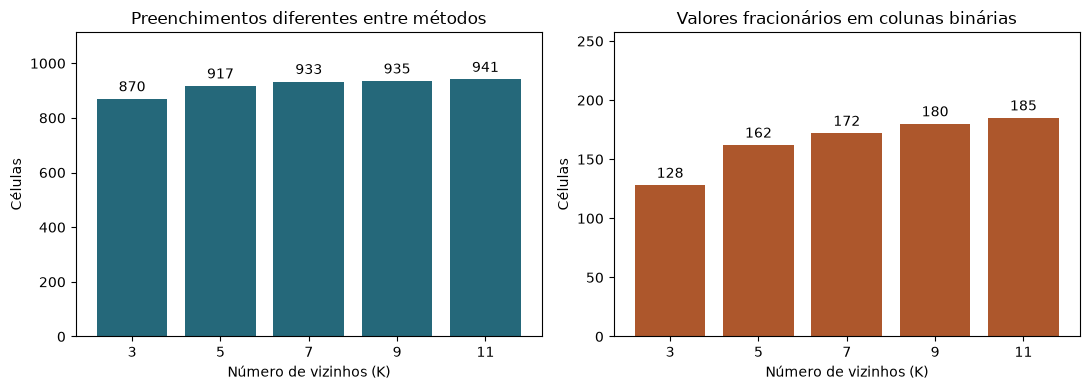

In [132]:


fig, (difference_ax, binary_ax) = plt.subplots(1, 2, figsize=(11, 4))
k_labels = sklearn_comparison.index.astype(str)

bars = difference_ax.bar(
    k_labels, sklearn_comparison["Preenchimentos diferentes"], color="#25687a"
)
difference_ax.bar_label(bars, padding=3)
difference_ax.set(
    title="Preenchimentos diferentes entre métodos",
    xlabel="Número de vizinhos (K)",
    ylabel="Células",
    ylim=(0, sklearn_comparison["Células imputadas"].iloc[0] * 1.1),
)

bars = binary_ax.bar(
    k_labels, sklearn_comparison["Binários fracionários no scikit-learn"], color="#ad572c"
)
binary_ax.bar_label(bars, padding=3)
binary_ax.set(
    title="Valores fracionários em colunas binárias",
    xlabel="Número de vizinhos (K)",
    ylabel="Células",
    ylim=(0, missing_mask[binary_columns].sum().sum() * 1.1),
)

fig.tight_layout()
plt.show()

### Observações sobre a comparação com o scikit-learn

- **Variáveis binárias.** Para uma coluna como `rbc`, se os três vizinhos têm valores `[0, 1, 0]`, o método do artigo usa a moda e preenche o faltante com `0`. Já o `KNNImputer`, com pesos uniformes, usa a média e devolve aproximadamente `0,33`. Esse valor representa a proporção de vizinhos com código `1`, mas fica fora das categorias permitidas para `rbc`. Um ajuste possível é atribuir `1` quando a média for maior que `0,5` e `0` quando for menor. Em caso de empate, podemos adotar `0` como critério de desempate.
- **Seleção dos vizinhos.** O artigo utiliza apenas pacientes com todos os preditores preenchidos. O `KNNImputer` também pode usar pacientes incompletos que tenham valor na coluna a imputar. Por exemplo, para preencher `rbc`, um paciente com `rbc` observado pode ser vizinho mesmo que sua idade esteja faltando.
- **Cálculo da distância.** O `KNNImputer` compara os pacientes usando as colunas observadas em ambos e ajusta a distância pela quantidade dessas colunas.

Essas diferenças ajudam a explicar por que os métodos produzem preenchimentos distintos. Para a replicação, mantemos o método do artigo, que preserva as categorias binárias. Adotamos a padronização dos preditores numéricos como hipótese, pois o artigo não especifica se ela foi aplicada na imputação.

In [133]:


X_model = scaled_imputed_by_k[9]
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=1234)

train_index, test_index = next(cv.split(X_model, y))

print("Treino:", len(train_index))
print("Teste:", len(test_index))

Treino: 300
Teste: 100


## Importância das variáveis na random forest

Na seção II-C, Qin et al. ajustam a random forest na base completa e consideram redundantes, para esse critério, as variáveis com contribuição zero para a redução da impureza Gini. A Figura 2 usa a base imputada com `K = 9`. Os autores relatam importância zero para `pcc`, `ba` e `cad`.

A replicação usa a base imputada com padronização e uma floresta de 500 árvores, com semente 1234. No scikit-learn, `feature_importances_` mede a redução ponderada de impureza e normaliza as importâncias para que somem 1. A escala do gráfico é, portanto, a do scikit-learn. O artigo usa o pacote `randomForest` do R.

[Figura 2 e seção II-C](../artigo/A_Machine_Learning_Methodology_for_Diagnosing_Chronic_Kidney_Disease.pdf) · [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

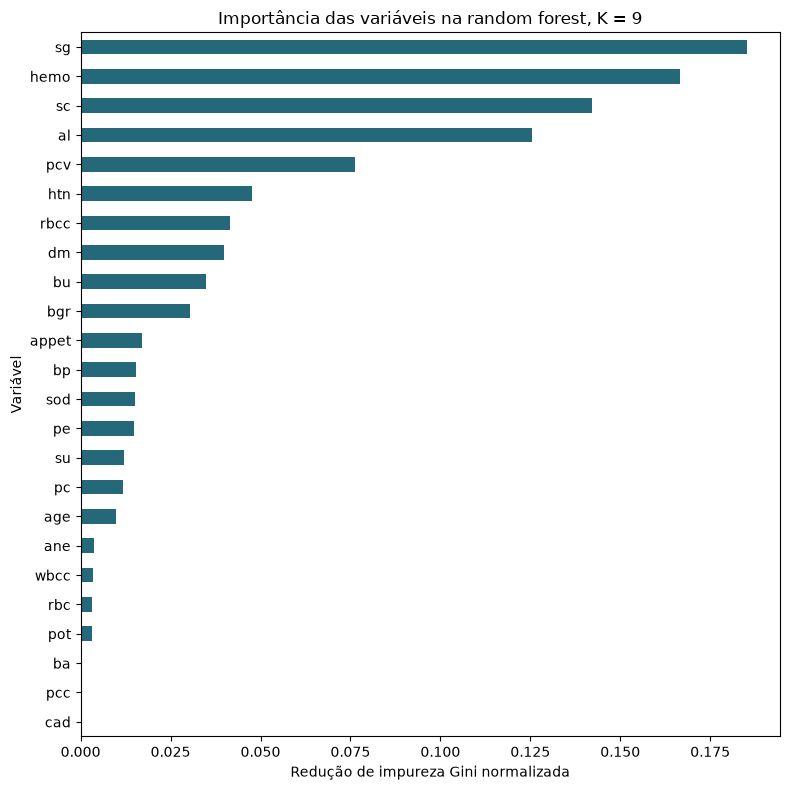

Importância exatamente zero: ['cad']


,Importância Gini
pcc,0.000201
ba,0.000291
cad,0.000000


In [ ]:
X_importance = scaled_imputed_by_k[9]
forest = RandomForestClassifier(
    n_estimators=500, criterion="gini", max_features="sqrt", random_state=1234
)
forest.fit(X_importance, y)

importance = pd.Series(forest.feature_importances_, index=X_importance.columns)
zero_importance = importance.index[importance.eq(0)].tolist()
article_removed = ["pcc", "ba", "cad"]

ordered_importance = importance.sort_values()
bar_colors = [
    "#ad572c" if column in article_removed else "#25687a"
    for column in ordered_importance.index
]
fig_importance, ax = plt.subplots(figsize=(8, 8))
ordered_importance.plot.barh(ax=ax, color=bar_colors)
ax.set(
    title="Importância das variáveis na random forest, K = 9",
    xlabel="Redução de impureza Gini normalizada",
    ylabel="Variável",
)
fig_importance.tight_layout()
plt.show()

print("Importância exatamente zero:", zero_importance)
importance.loc[article_removed].to_frame("Importância Gini")

### Desempenho com e sem as variáveis descartadas

Usamos as mesmas quatro dobras estratificadas para comparar três conjuntos de preditores: todos, sem as variáveis de importância zero nesta execução, e sem `pcc`, `ba` e `cad`, conforme a lista publicada. A base foi imputada antes de dividir as dobras, seguindo a ordem do artigo. A importância deste gráfico foi calculada com a base inteira. Para avaliar uma regra de seleção de variáveis sem usar informação do teste, a seleção deve ser refeita dentro de cada dobra.

In [135]:


importance_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=1234)
folds = list(importance_cv.split(X_importance, y))

feature_sets = {
    "Todos os preditores": X_importance,
    "Sem importância zero nesta execução": X_importance.drop(columns=zero_importance),
    "Sem pcc, ba e cad": X_importance.drop(columns=article_removed),
}
performance_rows = []
confusion_rows = []

for name, features in feature_sets.items():
    predictions = cross_val_predict(forest, features, y, cv=folds)
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=["notckd", "ckd"]).ravel()
    confusion_rows.append({
        "Preditores": name,
        "VP": tp,
        "FP": fp,
        "FN": fn,
        "VN": tn,
    })
    performance_rows.append({
        "Preditores": name,
        "Acurácia (%)": 100 * accuracy_score(y, predictions),
        "Sensibilidade (%)": 100 * tp / (tp + fn),
        "Especificidade (%)": 100 * tn / (tn + fp),
        "F1 (%)": 100 * f1_score(y, predictions, pos_label="ckd"),
        "Erros": fp + fn,
    })

importance_comparison = pd.DataFrame(performance_rows).set_index("Preditores").round(2)
importance_comparison

,Acurácia (%),Sensibilidade (%),Especificidade (%),F1 (%),Erros
Preditores,,,,,
Todos os preditores,99.75,99.6,100.0,99.8,1
Sem importância zero nesta execução,99.75,99.6,100.0,99.8,1
"Sem pcc, ba e cad",99.75,99.6,100.0,99.8,1


### Matriz de confusão nas quatro dobras

As contagens reúnem as previsões feitas no teste de cada dobra. Cada paciente aparece uma vez, e `ckd` é a classe positiva.

- **VP** (verdadeiro positivo) — paciente `ckd` previsto como `ckd`.
- **FP** (falso positivo) — paciente `notckd` previsto como `ckd`.
- **FN** (falso negativo) — paciente `ckd` previsto como `notckd`.
- **VN** (verdadeiro negativo) — paciente `notckd` previsto como `notckd`.

In [136]:
confusion_counts = pd.DataFrame(confusion_rows).set_index("Preditores")
confusion_counts

,VP,FP,FN,VN
Preditores,,,,
Todos os preditores,249,0,1,150
Sem importância zero nesta execução,249,0,1,150
"Sem pcc, ba e cad",249,0,1,150


## Replicação da Tabela 5 — acurácia da random forest

A comparação usa os 24 preditores, 500 árvores e quatro dobras estratificadas com semente 1234. A imputação acontece antes da divisão, conforme o protocolo do artigo. Para o KNN, adotamos a hipótese de padronização dos preditores numéricos ao buscar vizinhos.

A imputação por média e moda usa a média nas numéricas e a moda nas categóricas. Para a imputação aleatória, adotamos o sorteio com reposição entre os valores observados da própria coluna e calculamos a média de cinco rodadas. O artigo informa o número de rodadas, mas não detalha a distribuição do sorteio. Os resultados são comparados com a coluna RF da Tabela 5.

[Artigo original, Tabela 5](../artigo/A_Machine_Learning_Methodology_for_Diagnosing_Chronic_Kidney_Disease.pdf)

In [137]:
def evaluate_rf(features, splits, seed):
    model = clone(forest).set_params(random_state=seed)
    predictions = cross_val_predict(model, features, y, cv=splits)
    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=["notckd", "ckd"]
    ).ravel()
    return {
        "Acurácia (%)": 100 * accuracy_score(y, predictions),
        "Sensibilidade (%)": 100 * tp / (tp + fn),
        "Especificidade (%)": 100 * tn / (tn + fp),
        "F1 (%)": 100 * f1_score(y, predictions, pos_label="ckd"),
        "Erros": fp + fn,
    }


mean_mode_features = X.astype(float)
for column in mean_mode_features:
    values = mean_mode_features[column]
    fill_value = (
        values.mode().iloc[0] if column in categorical_columns else values.mean()
    )
    mean_mode_features[column] = values.fillna(fill_value)

table5_inputs = {f"KNN (K = {k})": scaled_imputed_by_k[k] for k in neighbor_counts}
table5_inputs["Média e moda"] = mean_mode_features
table5_results = {
    name: evaluate_rf(features, folds, seed=1234)
    for name, features in table5_inputs.items()
}

rng = np.random.default_rng(1234)
random_runs = []
for _ in range(5):
    random_features = X.copy()
    for column in random_features:
        missing = X[column].isna()
        observed = X.loc[~missing, column]
        random_features.loc[missing, column] = rng.choice(
            observed.to_numpy(), size=int(missing.sum()), replace=True
        )
    random_runs.append(evaluate_rf(random_features, folds, seed=1234))

table5_results["Aleatória (média de 5 rodadas)"] = pd.DataFrame(random_runs).mean()
table5_reference = pd.Series(
    [99.75, 99.75, 99.50, 99.75, 99.50, 98.75, 97.85],
    index=list(table5_results),
)
table5_metrics = pd.DataFrame.from_dict(table5_results, orient="index")
table5_comparison = pd.DataFrame({
    "Artigo (%)": table5_reference,
    "Replicação (%)": table5_metrics["Acurácia (%)"],
    "Erros na replicação": table5_metrics["Erros"],
}).rename_axis("Imputação")
table5_comparison["Diferença (p.p.)"] = (
    table5_comparison["Replicação (%)"] - table5_comparison["Artigo (%)"]
)
table5_comparison.round(2)

,Artigo (%),Replicação (%),Erros na replicação,Diferença (p.p.)
Imputação,,,,
KNN (K = 3),99.75,99.75,1.0,0.00
KNN (K = 5),99.75,99.75,1.0,0.00
KNN (K = 7),99.50,99.75,1.0,0.25
KNN (K = 9),99.75,99.75,1.0,0.00
KNN (K = 11),99.50,99.75,1.0,0.25
Média e moda,98.75,99.00,4.0,0.25
Aleatória (média de 5 rodadas),97.85,98.35,6.6,0.50


## Replicação da Tabela 10 — médias em dez rodadas

A Tabela 10 publica médias de dez rodadas. Para cada `K`, repetimos a avaliação em quatro dobras estratificadas usando as sementes de 0 a 9 para a divisão e para a floresta. Usamos a mesma sequência para todos os valores de `K`, com 500 árvores e os 24 preditores. Em cada rodada, calculamos as métricas sobre as previsões de teste dos 400 pacientes, com `ckd` como classe positiva.

As dobras e as florestas são geradas pelo scikit-learn. O artigo usa R e informa que retirou a semente fixa 1234 para essas rodadas. A base foi imputada antes da validação para esta comparação com o artigo. A avaliação com imputação dentro das dobras está na seção sobre vazamento de dados.

[Artigo original, Tabela 10](../artigo/A_Machine_Learning_Methodology_for_Diagnosing_Chronic_Kidney_Disease.pdf)

In [138]:
table10_runs = []
for seed in range(10):
    repeated_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=seed)
    repeated_folds = list(repeated_cv.split(X, y))
    for k in neighbor_counts:
        metrics = evaluate_rf(scaled_imputed_by_k[k], repeated_folds, seed=seed)
        table10_runs.append({"K": k, "Semente": seed, **metrics})

table10_runs = pd.DataFrame(table10_runs)
metric_columns = ["Acurácia (%)", "Sensibilidade (%)", "Especificidade (%)", "F1 (%)"]
table10_means = table10_runs.groupby("K")[metric_columns].mean()

table10_reference = pd.DataFrame(
    [
        [99.58, 99.32, 100.00, 99.66],
        [99.75, 99.60, 100.00, 99.80],
        [99.68, 99.48, 100.00, 99.74],
        [99.65, 99.44, 100.00, 99.72],
        [99.73, 99.56, 100.00, 99.78],
    ],
    index=pd.Index(neighbor_counts, name="K"),
    columns=metric_columns,
)
table10_comparison = pd.concat(
    {"Artigo": table10_reference, "Replicação": table10_means}, axis=1
).swaplevel(axis=1)
table10_comparison = table10_comparison.reindex(
    columns=pd.MultiIndex.from_product([metric_columns, ["Artigo", "Replicação"]])
)
table10_comparison.round(2)

Acurácia (%)            Sensibilidade (%)            Especificidade (%)  \
         Artigo Replicação            Artigo Replicação             Artigo   
K                                                                            
3         99.58      99.52             99.32      99.24              100.0   
5         99.75      99.62             99.60      99.40              100.0   
7         99.68      99.62             99.48      99.40              100.0   
9         99.65      99.65             99.44      99.44              100.0   
11        99.73      99.65             99.56      99.44              100.0   

              F1 (%)             
   Replicação Artigo Replicação  
K                                
3       100.0  99.66      99.62  
5       100.0  99.80      99.70  
7       100.0  99.74      99.70  
9       100.0  99.72      99.72  
11      100.0  99.78      99.72

## Possível vazamento de dados na validação cruzada

Na avaliação anterior, imputamos o conjunto inteiro antes de separar as quatro dobras, seguindo a ordem descrita no artigo. Com isso, os pacientes do teste influenciaram a média e o desvio-padrão usados na padronização. Os pacientes completos do teste também puderam servir de vizinhos para preencher valores do treino. Essa troca de informação pode acontecer mesmo com a coluna `class` separada.

Na segunda avaliação, primeiro dividimos treino e teste em cada dobra. Calculamos a padronização apenas com o treino e buscamos vizinhos somente entre os pacientes completos do treino. Usamos essa mesma referência para preencher os faltantes do treino e do teste. Depois, treinamos a random forest e prevemos os rótulos do teste.

Para isolar a mudança no momento da imputação, usamos as mesmas quatro dobras, os 24 preditores, `K = 9`, a mesma regra de imputação e a mesma configuração da floresta. A classe positiva é `ckd`.

In [139]:


fold_predictions = pd.Series(index=y.index, dtype=y.dtype)

for train_indices, test_indices in folds:
    X_train = X.iloc[train_indices]
    X_test = X.iloc[test_indices]
    y_train = y.iloc[train_indices]

    X_train_imputed = impute_knn(X_train, 9, categorical_columns, standardize=True)
    X_test_imputed = impute_knn(
        X_test, 9, categorical_columns, standardize=True, reference=X_train
    )

    fold_forest = clone(forest)
    fold_forest.fit(X_train_imputed, y_train)
    fold_predictions.iloc[test_indices] = fold_forest.predict(X_test_imputed)

tn, fp, fn, tp = confusion_matrix(
    y, fold_predictions, labels=["notckd", "ckd"]
).ravel()

before = pd.concat([
    importance_comparison.loc["Todos os preditores"],
    confusion_counts.loc["Todos os preditores"],
])
after = {
    "Acurácia (%)": 100 * accuracy_score(y, fold_predictions),
    "Sensibilidade (%)": 100 * tp / (tp + fn),
    "Especificidade (%)": 100 * tn / (tn + fp),
    "F1 (%)": 100 * f1_score(y, fold_predictions, pos_label="ckd"),
    "Erros": fp + fn,
    "VP": tp,
    "FP": fp,
    "FN": fn,
    "VN": tn,
}

leakage_comparison = pd.DataFrame({
    "Imputação antes de dividir as dobras": before,
    "Imputação dentro de cada dobra": after,
}).T.round(2)

count_columns = ["Erros", "VP", "FP", "FN", "VN"]
leakage_comparison = leakage_comparison.astype(dict.fromkeys(count_columns, int))
leakage_comparison

,Acurácia (%),Sensibilidade (%),Especificidade (%),F1 (%),Erros,VP,FP,FN,VN
Imputação antes de dividir as dobras,99.75,99.6,100.0,99.8,1,249,0,1,150
Imputação dentro de cada dobra,99.75,99.6,100.0,99.8,1,249,0,1,150


## 7.2 — Variação entre divisões das dobras

Neste teste, variamos somente a semente que sorteia as quatro dobras. A floresta mantém 500 árvores e semente 1234. Para cada semente de divisão, usamos as mesmas dobras para os cinco valores de `K` e para média/moda. As tabelas imputadas são as mesmas da replicação da Tabela 5.

A primeira tabela mostra a variação da acurácia entre as dez divisões. A segunda compara os métodos dentro das mesmas divisões. As duas usam pontos percentuais nas diferenças. Com 400 pacientes, a acurácia muda 0,25 ponto percentual a cada erro adicional.

In [ ]:
split_variability_rows = []
for split_seed in range(10):
    splitter = StratifiedKFold(n_splits=4, shuffle=True, random_state=split_seed)
    split_folds = list(splitter.split(X, y))

    for method, features in table5_inputs.items():
        metrics = evaluate_rf(features, split_folds, seed=1234)
        split_variability_rows.append({
            "Imputação": method,
            "Semente das dobras": split_seed,
            **metrics,
        })

split_variability_runs = pd.DataFrame(split_variability_rows)
split_variability = (
    split_variability_runs.groupby("Imputação")["Acurácia (%)"]
    .agg(Média="mean", DP="std", Mínimo="min", Máximo="max")
    .reindex(table5_inputs)
)
split_variability["Amplitude (p.p.)"] = (
    split_variability["Máximo"] - split_variability["Mínimo"]
)
split_variability.round(3)

,Média,DP,Mínimo,Máximo,Amplitude (p.p.)
Imputação,,,,,
KNN (K = 3),99.625,0.212,99.25,99.75,0.50
KNN (K = 5),99.675,0.121,99.50,99.75,0.25
KNN (K = 7),99.675,0.121,99.50,99.75,0.25
KNN (K = 9),99.725,0.079,99.50,99.75,0.25
KNN (K = 11),99.700,0.105,99.50,99.75,0.25
Média e moda,99.075,0.313,98.50,99.50,1.00


In [ ]:
accuracy_by_split = split_variability_runs.pivot(
    index="Semente das dobras", columns="Imputação", values="Acurácia (%)"
)
knn_methods = [f"KNN (K = {k})" for k in neighbor_counts]
paired_differences = accuracy_by_split[knn_methods].sub(
    accuracy_by_split["Média e moda"], axis=0
)
paired_summary = paired_differences.agg(["mean", "min", "max"]).T
paired_summary.columns = ["Média (p.p.)", "Mínimo (p.p.)", "Máximo (p.p.)"]

knn_spread = accuracy_by_split[knn_methods].max(axis=1) - accuracy_by_split[knn_methods].min(axis=1)
paired_summary.loc["Maior menos menor acurácia entre os K"] = [
    knn_spread.mean(), knn_spread.min(), knn_spread.max()
]
paired_summary.round(3)

,Média (p.p.),Mínimo (p.p.),Máximo (p.p.)
Imputação,,,
KNN (K = 3),0.550,-0.25,1.00
KNN (K = 5),0.600,0.00,1.00
KNN (K = 7),0.600,0.00,1.00
KNN (K = 9),0.650,0.00,1.25
KNN (K = 11),0.625,0.00,1.25
Maior menos menor acurácia entre os K,0.100,0.00,0.50


### Referências da Tabela 11

A tabela mostra alguns dos resultados publicados na Tabela 11 e a diferença em relação à acurácia média da nossa random forest com `K = 9`. A amplitude observada entre as nossas divisões aparece na primeira tabela desta seção. A comparação com trabalhos anteriores usa valores publicados de outros experimentos, com protocolos de avaliação próprios.

[Artigo original, Tabela 11](../artigo/A_Machine_Learning_Methodology_for_Diagnosing_Chronic_Kidney_Disease.pdf)

In [ ]:
table11_reference = pd.Series({
    "RF [2]": 100.00,
    "SVM com seleção [6]": 99.50,
    "SVM [27]": 99.70,
    "MLP [29]": 99.75,
    "Rede neural [30]": 99.75,
}, name="Artigo (%)")
replicated_mean = split_variability.loc["KNN (K = 9)", "Média"]

table11_context = table11_reference.to_frame()
table11_context["Replicação K = 9 (%)"] = replicated_mean
table11_context["Replicação menos artigo (p.p.)"] = replicated_mean - table11_reference
table11_context.round(3)

,Artigo (%),Replicação K = 9 (%),Replicação menos artigo (p.p.)
RF [2],100.00,99.725,-0.275
SVM com seleção [6],99.50,99.725,0.225
SVM [27],99.70,99.725,0.025
MLP [29],99.75,99.725,-0.025
Rede neural [30],99.75,99.725,-0.025


## 7.3 — Quanto cada variável contribui para a distância

Para cada paciente incompleto, calculamos as diferenças ao quadrado em cada preditor observado, comparando-o com cada um dos 158 candidatos completos. A contribuição de um preditor é sua parcela na soma dessas diferenças, antes de tirar a raiz. Primeiro agregamos os candidatos de cada paciente e depois fazemos a média entre os pacientes, dando o mesmo peso a cada um.

A tabela compara a distribuição dessas contribuições nas escalas originais e com padronização dos preditores numéricos. A padronização do artigo permanece uma hipótese, pois o texto descreve a distância euclidiana sem informar o argumento de escala da imputação.

In [ ]:
def mean_squared_distance_share(distance_data):
    candidates = distance_data.loc[X.dropna().index]
    shares = []

    for _, patient in distance_data.loc[X.isna().any(axis=1)].iterrows():
        observed = patient.dropna()
        squared_differences = candidates[observed.index].sub(observed).pow(2)
        contribution = squared_differences.sum(axis=0).reindex(X.columns, fill_value=0)
        shares.append(contribution / contribution.sum())

    return pd.DataFrame(shares).mean() * 100


distance_contributions = pd.DataFrame({
    "Amplitude original": X.max() - X.min(),
    "Escala original (%)": mean_squared_distance_share(X.astype(float)),
    "Com padronização (%)": mean_squared_distance_share(scaled_X),
}).sort_values("Escala original (%)", ascending=False)

distance_contributions.round(3)

,Amplitude original,Escala original (%),Com padronização (%)
wbcc,24200.0,56.130,4.710
bgr,468.0,21.603,6.707
bu,389.5,15.554,7.147
age,88.0,3.912,9.709
bp,130.0,1.773,7.858
pcv,45.0,0.445,6.511
sod,158.5,0.261,2.899
sc,75.6,0.166,3.133
hemo,14.7,0.068,7.819
pot,44.5,0.038,4.220


## 7.4 — Classes dos candidatos a vizinhos e valores imputados

Contamos os pacientes completos em cada classe. Depois, para `K = 9` com padronização, comparamos os valores preenchidos nos pacientes `ckd` com os valores originalmente observados em cada classe.

Para preditores numéricos, a comparação usa a mediana. Para categóricos, usa o percentual com código 1. Os números de valores disponíveis aparecem em cada linha. A classe serve apenas para descrever os grupos nesta análise.


O traço indica que o grupo não tem valores para a medida naquela variável.

In [ ]:
complete_mask = X.notna().all(axis=1)
donor_counts = pd.DataFrame({
    "Total na base": y.value_counts(),
    "Amostras completas": y.loc[complete_mask].value_counts(),
})
donor_counts["Participação nos completos (%)"] = (
    100 * donor_counts["Amostras completas"] / complete_mask.sum()
)
donor_counts.round(2)

,Total na base,Amostras completas,Participação nos completos (%)
class,,,
ckd,250,43,27.215
notckd,150,115,72.785


In [ ]:
donor_comparison_rows = []
for column in X.columns:
    observed_ckd = X.loc[y.eq("ckd"), column].dropna()
    observed_notckd = X.loc[y.eq("notckd"), column].dropna()
    missing_ckd = y.eq("ckd") & X[column].isna()
    imputed_ckd = scaled_imputed_by_k[9].loc[missing_ckd, column]

    if column in categorical_columns:
        statistic = "% com código 1"
        values = [100 * series.mean() for series in (observed_ckd, observed_notckd, imputed_ckd)]
    else:
        statistic = "Mediana"
        values = [series.median() for series in (observed_ckd, observed_notckd, imputed_ckd)]

    donor_comparison_rows.append({
        "Variável": column,
        "Medida": statistic,
        "Observado em ckd": values[0],
        "Observado em notckd": values[1],
        "Imputado em ckd": round(float(values[2]), 3) if len(imputed_ckd) else "—",
        "N observado ckd": len(observed_ckd),
        "N observado notckd": len(observed_notckd),
        "N imputado ckd": len(imputed_ckd),
    })

donor_imputation_comparison = pd.DataFrame(donor_comparison_rows).set_index("Variável")
donor_imputation_comparison.round(3)

,Medida,Observado em ckd,Observado em notckd,Imputado em ckd,N observado ckd,N observado notckd,N imputado ckd
Variável,,,,,,,
age,Mediana,59.000,46.00,60.0,242,149,8
bp,Mediana,80.000,70.00,70.0,240,148,10
sg,Mediana,1.015,1.02,1.015,208,145,42
al,Mediana,2.000,0.00,3.0,209,145,41
su,Mediana,0.000,0.00,0.0,206,145,44
rbc,% com código 1,56.075,100.00,81.119,107,141,143
pc,% com código 1,60.825,100.00,39.286,194,141,56
pcc,% com código 1,16.800,0.00,—,250,146,0
ba,% com código 1,8.800,0.00,—,250,146,0
